# Deep Reinforcement Learning — Hands-on Practice Set (SOLUTIONS)

Hands-on exercises that follow the **Deep Reinforcement Learning** slides. You will go from the agent–environment loop and tabular Q-learning to **DQN**, **REINFORCE**, **PPO** and the exploration problem, and finally *see* reward hacking happen.

| # | Exercise | Slide | Approx. CPU time |
|---|---|---|---|
| 1 | The agent–environment loop (random agent on CartPole) | 2 | < 5 s |
| 2 | Discounted return Gₜ | 3 | < 1 s |
| 3 | Tabular Q-learning on FrozenLake | 4 | ~ 10 s |
| 4 | Why tables break down | 5 | < 2 s |
| 5 | Deep Q-Network (replay buffer + target network) | 7 | 1–3 min |
| 6 | Overestimation and the Double DQN target | 8 | < 1 s |
| 7 | REINFORCE, with and without a baseline | 9 | ~ 80 s |
| 8 | PPO's clipped objective + PPO with Stable-Baselines3 | 10, 11, 15 | ~ 60 s |
| 9 | Exploration: ε-greedy on a 10-armed bandit | 13 | ~ 5 s |
| 10 | Challenge: reward hacking in a corridor | 16 | < 5 s |

**How to use this notebook**

* Lines marked `# TODO:` contain `...`; replace it with your answer.
* Run the **check** cell after each exercise. It prints `PASS` or a hint.
* Everything runs on a laptop CPU or free Colab. The environments come with `gymnasium`, so nothing else needs downloading.
* RL is noisy: a different random seed can give a different score. If a check fails by a small margin, re-run the training cell.

In [1]:
# !pip install gymnasium stable-baselines3   # uncomment on Colab / first run
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt
import random, copy, time, collections
torch.manual_seed(0); np.random.seed(0); random.seed(0)

def check(ok, good, hint):
    print(("PASS: " + good) if ok else ("NOT YET: " + hint))

def smooth(x, k=20):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) >= k else x

print("gymnasium", gym.__version__, "| torch", torch.__version__)

gymnasium 1.4.0 | torch 2.15.0+cu132


---
## Exercise 1. The agent–environment loop (slide 2)

**CartPole-v1:** push a cart left or right to keep a pole upright.

* **State** (4 numbers): cart position, cart velocity, pole angle, pole angular velocity
* **Actions**: 0 = push left, 1 = push right
* **Reward**: +1 for every step the pole stays up; the episode ends when it falls (*terminated*) or after 500 steps (*truncated*)

Gymnasium's `step` returns **five** values: `next_state, reward, terminated, truncated, info`.

**Task:** complete the loop and measure how well a **random agent** does.

In [2]:
env = gym.make("CartPole-v1")
print("observation space:", env.observation_space)
print("action space:", env.action_space)

def run_episode(env, policy, seed=None):
    state, _ = env.reset(seed=seed)
    total, done = 0.0, False
    while not done:
        action = policy(state)
        state, reward, terminated, truncated, _ = env.step(action)  # TODO: take one step in the environment
        total += reward
        done = terminated or truncated  # TODO: the episode ends when it is terminated OR truncated
    return total

env.action_space.seed(0)
random_policy = lambda s: env.action_space.sample()
random_returns = [run_episode(env, random_policy, seed=i) for i in range(50)]
print(f"Random agent: mean return {np.mean(random_returns):.1f} (max possible 500)")

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2)
Random agent: mean return 25.1 (max possible 500)


In [3]:
check(10 < np.mean(random_returns) < 40,
      "a random agent keeps the pole up for only about 20 steps. Learning must do much better.",
      "state, reward, terminated, truncated, _ = env.step(action); done = terminated or truncated.")

PASS: a random agent keeps the pole up for only about 20 steps. Learning must do much better.


---
## Exercise 2. The discounted return (slide 3)

`Gₜ = rₜ₊₁ + γ rₜ₊₂ + γ² rₜ₊₃ + …`

The trick is to compute it **backwards**: `G = r + γ · G_next`. Every RL algorithm in this notebook uses this.

**Task:** return the list `[G₀, G₁, …]` for every time step of an episode.

In [4]:
def discounted_returns(rewards, gamma):
    G, out = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G  # TODO: backward recursion
        out.append(G)
    return out[::-1]

print(discounted_returns([1, 1, 1], 0.9))     # slide 3 example
print(discounted_returns([2, 0, 4], 0.5))     # quiz question 1 from the summary slide

[2.71, 1.9, 1.0]
[3.0, 2.0, 4.0]


In [5]:
check(np.allclose(discounted_returns([1, 1, 1], 0.9), [2.71, 1.9, 1.0]) and np.isclose(discounted_returns([2, 0, 4], 0.5)[0], 3.0),
      "G0 = 2.71 for the slide example and 3.0 for the quiz question.",
      "G = r + gamma * G, looping over the rewards in reverse.")

PASS: G0 = 2.71 for the slide example and 3.0 for the quiz question.


**Think about it:** in CartPole every reward is +1. With γ = 0.99, what is the largest possible G₀ for a very long episode? (Hint: 1 + γ + γ² + … = 1 / (1 − γ).)

---
## Exercise 3. Tabular Q-learning on FrozenLake (slide 4)

**FrozenLake 4×4:** walk from **S** to the goal **G** across frozen tiles **F** without falling into holes **H**. Reward is 1 only at the goal.
There are just 16 states × 4 actions, so a **table** works.

Q-learning update (Watkins, 1989):

`Q(s,a) ← Q(s,a) + α [ r + γ · maxₐ′ Q(s′,a′) − Q(s,a) ]`   (no future term when the episode has *terminated*)

**Tasks:** write ε-greedy action selection and the update. Then train on the normal lake and on the **slippery** lake, where your move only goes the way you intended one time in three.

In [6]:
def epsilon_greedy(Q, s, eps, n_actions):
    if np.random.rand() < eps:
        return np.random.randint(n_actions)
    best = np.flatnonzero(Q[s] == Q[s].max())          # break ties randomly
    return int(np.random.choice(best))

def q_learning(env, episodes=3000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_end=0.05):
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA))
    for ep in range(episodes):
        eps = max(eps_end, eps_start - ep / (0.6 * episodes))   # explore a lot at first, then less
        s, _ = env.reset(seed=ep)
        done = False
        while not done:
            a = epsilon_greedy(Q, s, eps, nA)
            s2, r, terminated, truncated, _ = env.step(a)
            target = r + gamma * Q[s2].max() * (not terminated)  # TODO: TD target (no future value if terminated)
            Q[s, a] = Q[s, a] + alpha * (target - Q[s, a])  # TODO: move Q(s,a) a step alpha towards the target
            s, done = s2, terminated or truncated
    return Q

def success_rate(env, Q, n=500):
    wins = 0
    for i in range(n):
        s, _ = env.reset(seed=10_000 + i); done = False
        while not done:
            s, r, terminated, truncated, _ = env.step(int(Q[s].argmax())); done = terminated or truncated
        wins += r
    return wins / n

def show_policy(Q, desc):
    arrows = np.array(["←", "↓", "→", "↑"])
    grid = [[c.decode() for c in row] for row in desc]
    for i in range(4):
        print(" ".join(grid[i][j] if grid[i][j] in "HG" else arrows[Q[4 * i + j].argmax()] for j in range(4)))

np.random.seed(0)
lake = gym.make("FrozenLake-v1", is_slippery=False)
Q_lake = q_learning(lake)
lake_success = success_rate(lake, Q_lake)
print(f"Non-slippery lake: success rate {lake_success:.0%}"); show_policy(Q_lake, lake.unwrapped.desc)

slippery = gym.make("FrozenLake-v1", is_slippery=True)
Q_slip = q_learning(slippery, episodes=20000, alpha=0.05)
slip_success = success_rate(slippery, Q_slip)
print(f"\nSlippery lake: success rate {slip_success:.0%}"); show_policy(Q_slip, slippery.unwrapped.desc)

Non-slippery lake: success rate 100%
↓ ← ↓ ←
↓ H ↓ H
→ ↓ ↓ H
H → → G



Slippery lake: success rate 73%
← ↑ ↑ ↑
← H → H
↑ ↓ ← H
H → ↓ G


In [7]:
check(lake_success == 1.0 and slip_success > 0.5,
      f"perfect on the normal lake; {slip_success:.0%} on the slippery lake (a random walk scores about 1.5%).",
      "target = r + gamma * Q[s2].max() * (not terminated); Q[s,a] += alpha * (target - Q[s,a]).")

PASS: perfect on the normal lake; 73% on the slippery lake (a random walk scores about 1.5%).


**Think about it:** on the slippery lake the best policy often points *away* from the goal near holes (look at the arrows). Why is that sensible when moves are random? Even the optimal policy only wins about 74% of the time here.

---
## Exercise 4. Why tables break down (slide 5)

CartPole's state is 4 **real numbers**. How many *different* states does an agent see? Let's count the distinct states, even after rounding each number to 2 decimal places.

In [8]:
env = gym.make("CartPole-v1"); env.action_space.seed(0)
seen, steps = set(), 0
for ep in range(200):
    s, _ = env.reset(seed=ep); done = False
    while not done:
        seen.add(tuple(np.round(s, 2)))  # TODO: add the state rounded to 2 decimals (as a tuple) to the set
        s, r, te, tr, _ = env.step(env.action_space.sample()); done = te or tr; steps += 1
print(f"{steps} steps, {len(seen)} distinct rounded states ({len(seen) / steps:.0%} of all visits were to a state never seen before)")

4538 steps, 4473 distinct rounded states (99% of all visits were to a state never seen before)


In [9]:
check(len(seen) > 0.8 * steps,
      "almost every state is new, so a table would never see the same entry twice. We need a network that generalises.",
      "seen.add(tuple(np.round(s, 2))).")

PASS: almost every state is new, so a table would never see the same entry twice. We need a network that generalises.


---
## Exercise 5. Deep Q-Network (slide 7)

Replace the table with a neural network `Q(s, ·; θ)` that outputs one value per action, and add DQN's two stabilising tricks:

1. **Experience replay:** store transitions `(s, a, r, s′, done)` and train on **random** minibatches.
2. **Target network θ⁻:** a frozen copy used for the TD target, synced every 1,000 steps.

DQN agents can also suddenly get worse late in training ("catastrophic forgetting"), so, like the DQN paper, we **evaluate regularly and keep the best weights**.

Loss: `( r + γ · maxₐ′ Q(s′, a′; θ⁻) · (1 − done) − Q(s, a; θ) )²` (we use the Huber loss, a robust version of squared error, as DQN did).

**Tasks:** complete the replay buffer, the TD target and the target-network sync.

step   5000  eps 0.38  mean return (last 10 episodes)   40.8


step  10000  eps 0.05  mean return (last 10 episodes)  156.2


step  15000  eps 0.05  mean return (last 10 episodes)  106.5


step  20000  eps 0.05  mean return (last 10 episodes)  133.3



Greedy DQN agent: mean return 207 over 10 test episodes   (192 s)


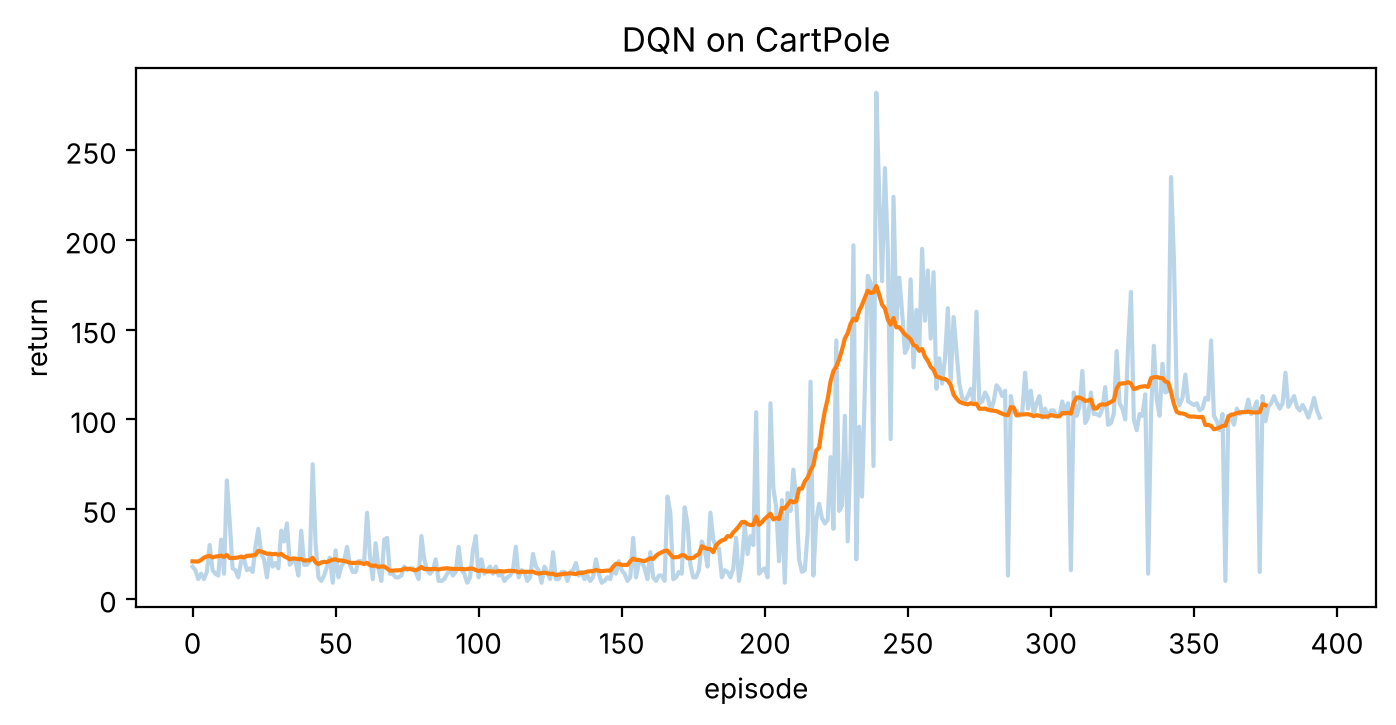

In [10]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = collections.deque(maxlen=capacity)     # oldest transitions are dropped automatically
    def push(self, s, a, r, s2, done):
        self.buffer.append((s, a, r, s2, done))  # TODO: store one transition as a tuple
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)  # TODO: draw batch_size random transitions
        s, a, r, s2, d = map(np.array, zip(*batch))
        return (torch.tensor(s, dtype=torch.float32), torch.tensor(a), torch.tensor(r, dtype=torch.float32),
                torch.tensor(s2, dtype=torch.float32), torch.tensor(d, dtype=torch.float32))
    def __len__(self):
        return len(self.buffer)

def make_qnet():
    return nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))

def standard_target(q_target, r, s2, done, gamma=0.99):
    with torch.no_grad():
        return r + gamma * q_target(s2).max(dim=1).values * (1 - done)  # TODO: r + gamma * max_a' Q_target(s', a') * (1 - done)

def greedy_score(q, n=5, seed=900):
    env = gym.make("CartPole-v1")
    with torch.no_grad():
        return float(np.mean([run_episode(env, lambda s: q(torch.tensor(s)).argmax().item(), seed=seed + i) for i in range(n)]))

def train_dqn(target_fn=standard_target, total_steps=25_000, seed=0, sync_every=1_000, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    env = gym.make("CartPole-v1"); env.action_space.seed(seed)
    q, buf = make_qnet(), ReplayBuffer(50_000)
    q_target = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=5e-4)
    s, _ = env.reset(seed=seed); ep_ret, returns = 0.0, []
    best_score, best_weights = -1.0, None
    for t in range(total_steps):
        eps = max(0.05, 1.0 - t / 8_000)                       # epsilon annealed from 1.0 to 0.05
        if random.random() < eps: a = env.action_space.sample()
        else:
            with torch.no_grad(): a = q(torch.tensor(s)).argmax().item()
        s2, r, terminated, truncated, _ = env.step(a)
        buf.push(s, a, r, s2, float(terminated))               # truncation is not a real "death"
        s, ep_ret = s2, ep_ret + r
        if terminated or truncated:
            returns.append(ep_ret); ep_ret = 0.0; s, _ = env.reset()
        if len(buf) >= 1_000:
            S, A, R, S2, D = buf.sample(64)
            y = target_fn(q_target, R, S2, D) if target_fn is standard_target else target_fn(q, q_target, R, S2, D)
            q_sa = q(S).gather(1, A.unsqueeze(1)).squeeze(1)
            loss = F.smooth_l1_loss(q_sa, y)
            opt.zero_grad(); loss.backward(); opt.step()
        if t % sync_every == 0:
            q_target.load_state_dict(q.state_dict())  # TODO: copy the online weights into the target network
        if t >= 8_000 and t % 1_000 == 0:                     # checkpoint: keep the best greedy agent so far
            score = greedy_score(q)
            if score > best_score: best_score, best_weights = score, copy.deepcopy(q.state_dict())
        if verbose and t % 5_000 == 0 and returns:
            print(f"step {t:6d}  eps {eps:.2f}  mean return (last 10 episodes) {np.mean(returns[-10:]):6.1f}")
    q.load_state_dict(best_weights)
    return q, returns

def evaluate(policy_fn, n=10):
    env = gym.make("CartPole-v1")
    return float(np.mean([run_episode(env, policy_fn, seed=500 + i) for i in range(n)]))

t0 = time.time()
q_net, dqn_returns = train_dqn()
dqn_score = evaluate(lambda s: q_net(torch.tensor(s)).argmax().item())
print(f"\nGreedy DQN agent: mean return {dqn_score:.0f} over 10 test episodes   ({time.time() - t0:.0f} s)")
plt.figure(figsize=(8, 3.5)); plt.plot(dqn_returns, alpha=0.3); plt.plot(smooth(dqn_returns))
plt.xlabel("episode"); plt.ylabel("return"); plt.title("DQN on CartPole"); plt.show()

In [11]:
check(dqn_score > 150,
      f"the DQN agent balances for {dqn_score:.0f} steps on average, against about 22 for the random agent.",
      "Check push/sample, the TD target with (1 - done), and q_target.load_state_dict(q.state_dict()). RL is noisy: try re-running.")

PASS: the DQN agent balances for 207 steps on average, against about 22 for the random agent.


**Try it:** set `sync_every=1` (no real target network) or shrink the buffer to 64 transitions (almost no replay) and re-train. What happens to the learning curve?

---
## Exercise 6. Overestimation and the Double DQN target (slide 8)

**Why does DQN overestimate?** Suppose all 10 actions have the true value 0, but our estimates have random noise. Taking the **max** of noisy estimates is biased **upwards**.

In [12]:
rng = np.random.default_rng(0)
noisy_Q = rng.normal(loc=0.0, scale=1.0, size=(100_000, 10))     # 100,000 states x 10 actions, true value 0
bias = noisy_Q.max(axis=1).mean()  # TODO: average over states of the max over actions
print(f"true max value = 0, average of max over noisy estimates = {bias:.2f}")

true max value = 0, average of max over noisy estimates = 1.54


**Double DQN** (van Hasselt et al., 2016): the **online** network *chooses* the next action, the **target** network *evaluates* it:

`y = r + γ · Q_target(s′, argmaxₐ′ Q_online(s′, a′)) · (1 − done)`

In [13]:
def double_target(q_online, q_target, r, s2, done, gamma=0.99):
    with torch.no_grad():
        best_a = q_online(s2).argmax(dim=1, keepdim=True)  # TODO: action chosen by the ONLINE network
        value = q_target(s2).gather(1, best_a).squeeze(1)  # TODO: evaluated by the TARGET network
        return r + gamma * value * (1 - done)

# Tiny hand-made example: 1 transition, 3 actions
online = lambda s: torch.tensor([[1.0, 5.0, 2.0]])     # online net thinks action 1 is best
target = lambda s: torch.tensor([[4.0, 3.0, 6.0]])     # target net's estimates
r, d, s2 = torch.tensor([1.0]), torch.tensor([0.0]), None
y_std = standard_target(target, r, s2, d, gamma=1.0)
y_dbl = double_target(online, target, r, s2, d, gamma=1.0)
print(f"standard target = 1 + max(4, 3, 6) = {y_std.item()}   |   double target = 1 + Q_target(action 1) = {y_dbl.item()}")

standard target = 1 + max(4, 3, 6) = 7.0   |   double target = 1 + Q_target(action 1) = 4.0


In [14]:
check(1.4 < bias < 1.7 and y_std.item() == 7.0 and y_dbl.item() == 4.0,
      f"max over noisy estimates is biased by about +{bias:.2f}; Double DQN uses 4 instead of the optimistic 6.",
      "bias = noisy_Q.max(axis=1).mean(); best_a from q_online(s2).argmax(1, keepdim=True); value = q_target(s2).gather(1, best_a).")

PASS: max over noisy estimates is biased by about +1.54; Double DQN uses 4 instead of the optimistic 6.


**Try it:** `train_dqn(target_fn=double_target)` trains a Double DQN agent. On a task as easy as CartPole the difference is small and depends on the seed; on Atari it was large.

---
## Exercise 7. REINFORCE: policy gradients (slide 9)

Instead of learning Q, learn the **policy** `πθ(a | s)` directly:

`∇J = 𝔼[ ∇ log πθ(aₜ | sₜ) · (Gₜ − b) ]`  →  in code, minimise `loss = − Σₜ log πθ(aₜ | sₜ) · (Gₜ − b)`

As the baseline `b` we use the simplest trick: **normalise the returns** of each episode (subtract the mean, divide by the standard deviation).

**Tasks:** sample an action and keep its log-probability; write the loss. Then compare **with** and **without** the baseline.

REINFORCE with baseline: last-20 mean 500 | without: 80 | greedy test score 500   (60 s)


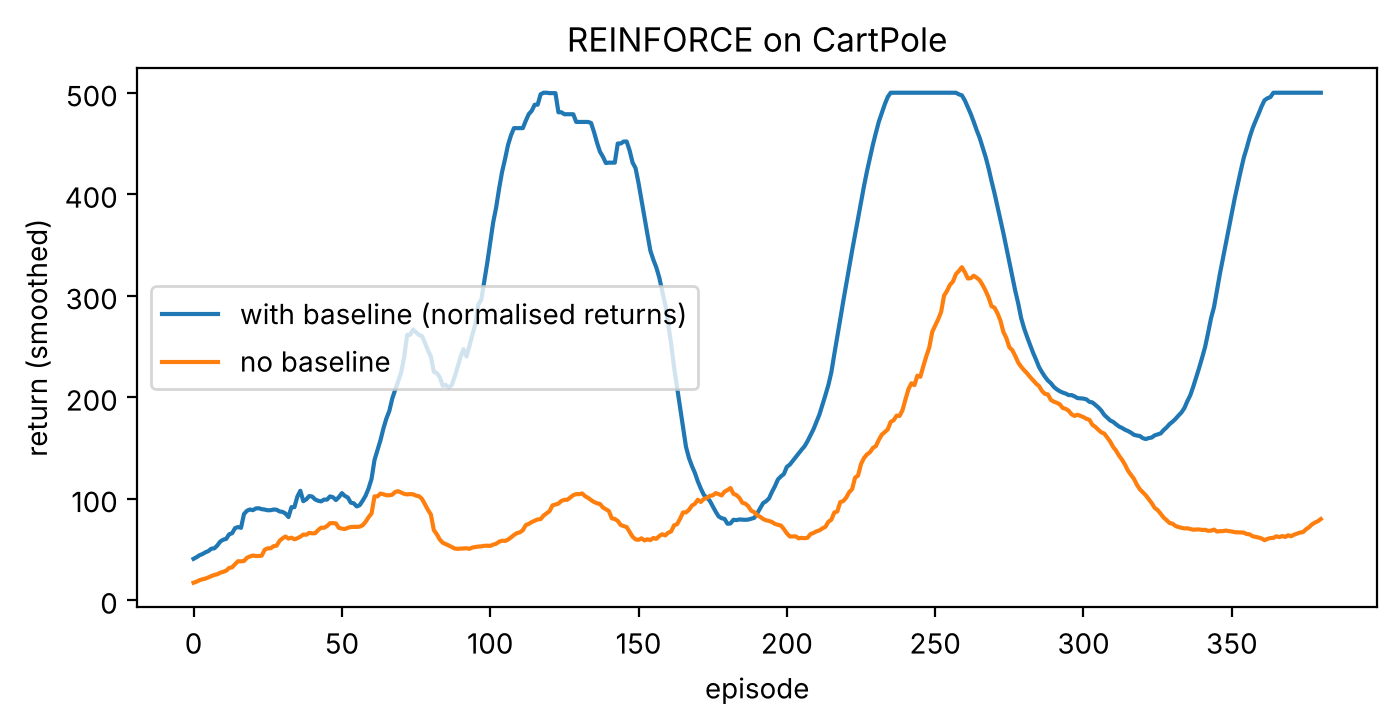

In [15]:
def train_reinforce(episodes=400, baseline=True, seed=0, gamma=0.99, lr=1e-2):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    policy = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 2))     # outputs action logits
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    history = []
    for ep in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + ep); log_probs, rewards, done = [], [], False
        while not done:
            dist = torch.distributions.Categorical(logits=policy(torch.tensor(s)))
            a = dist.sample()
            log_probs.append(dist.log_prob(a))  # TODO: log-probability of the sampled action
            s, r, terminated, truncated, _ = env.step(a.item())
            rewards.append(r); done = terminated or truncated
        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32)
        if baseline:
            G = (G - G.mean()) / (G.std() + 1e-8)
        loss = -(torch.stack(log_probs) * G).sum()  # TODO: policy-gradient loss
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(sum(rewards))
    return policy, history

t0 = time.time()
pg_policy, hist_base = train_reinforce(baseline=True)
_, hist_nobase = train_reinforce(baseline=False)
pg_score = evaluate(lambda s: pg_policy(torch.tensor(s)).argmax().item())
print(f"REINFORCE with baseline: last-20 mean {np.mean(hist_base[-20:]):.0f} | without: {np.mean(hist_nobase[-20:]):.0f} | greedy test score {pg_score:.0f}   ({time.time() - t0:.0f} s)")
plt.figure(figsize=(8, 3.5))
plt.plot(smooth(hist_base), label="with baseline (normalised returns)"); plt.plot(smooth(hist_nobase), label="no baseline")
plt.xlabel("episode"); plt.ylabel("return (smoothed)"); plt.legend(); plt.title("REINFORCE on CartPole"); plt.show()

In [16]:
check(pg_score > 150,
      f"the policy-gradient agent learned to balance (test score {pg_score:.0f}). Compare the two curves: the baseline usually learns faster.",
      "log_probs.append(dist.log_prob(a)); loss = -(torch.stack(log_probs) * G).sum(). If the return collapses to about 10, re-run with seed=1.")

PASS: the policy-gradient agent learned to balance (test score 500). Compare the two curves: the baseline usually learns faster.


**Note:** policy gradients are noisy. With a different seed the gap between the curves can shrink, and occasionally a run **collapses** (the policy becomes certain of a bad action and stops exploring). Running several seeds and plotting the average is standard practice.

**Think about it:** without the baseline every reward in CartPole is +1, so every return is positive. What does the gradient do to the probability of **every** action taken, including bad ones? Why does that make learning slow?

---
## Exercise 8. PPO's clipped objective (slides 10, 11 and 15)

Actor-critic methods replace `Gₜ − b` with the **advantage** `Aₜ ≈ r + γV(s′) − V(s)`. PPO (Schulman et al., 2017) then limits how far one update can move the policy:

`rₜ(θ) = πθ(aₜ|sₜ) / πθ_old(aₜ|sₜ)`    `L = 𝔼[ min( rₜ Aₜ, clip(rₜ, 1−ε, 1+ε) Aₜ ) ]`, ε = 0.2

**Task 1:** write the clipped objective and check it on the table of examples.

 ratio     A    r*A  PPO objective
   1.0   2.0    2.0           2.00
   1.5   2.0    3.0           2.40
   0.5   2.0    1.0           1.00
   1.5  -2.0   -3.0          -3.00
   0.5  -2.0   -1.0          -1.60


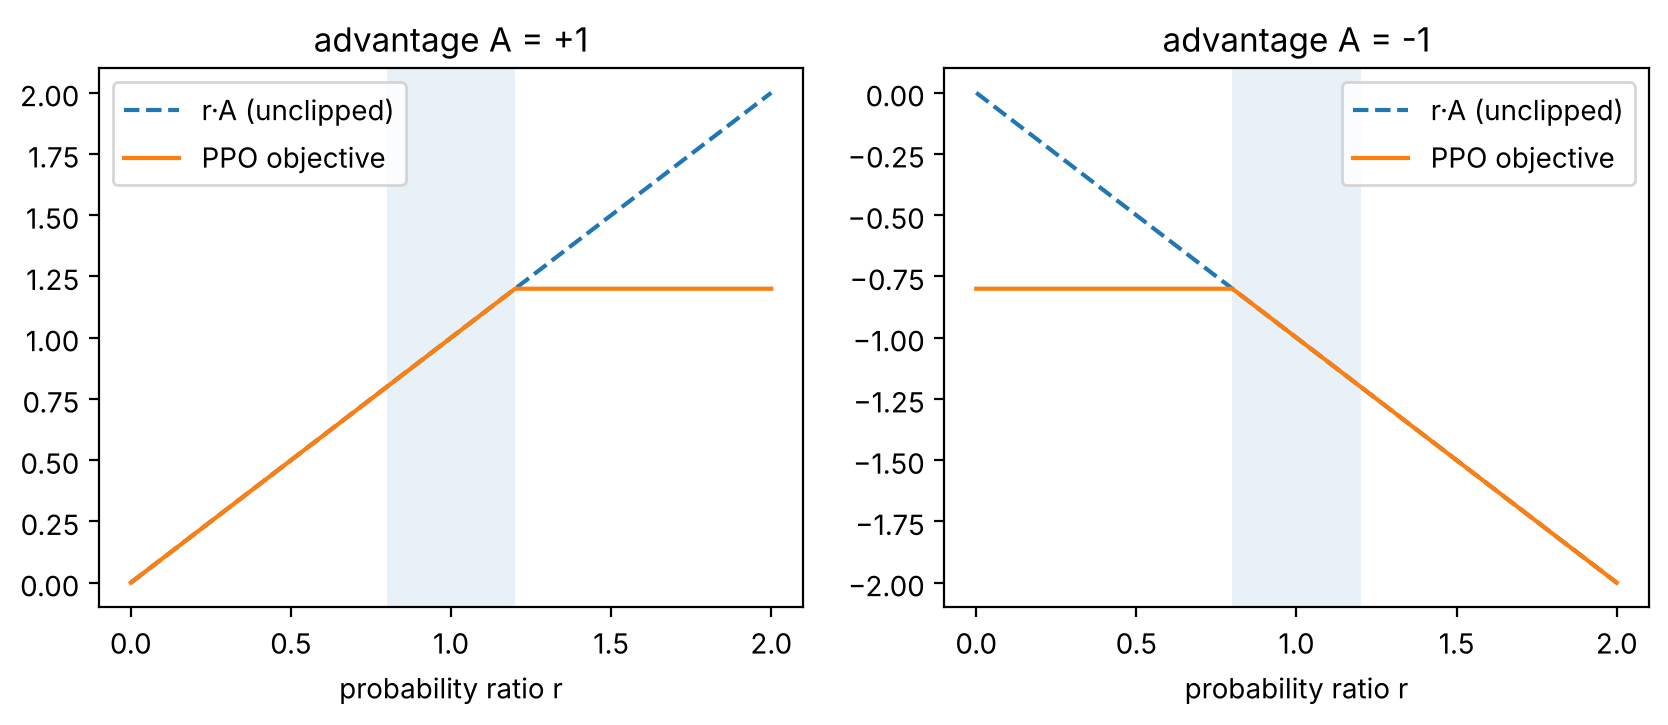

In [17]:
def ppo_objective(ratio, advantage, eps=0.2):
    unclipped = ratio * advantage
    clipped = torch.clamp(ratio, 1 - eps, 1 + eps) * advantage  # TODO: clip the ratio to [1 - eps, 1 + eps], times the advantage
    return torch.min(unclipped, clipped)  # TODO: the pessimistic (smaller) of the two

cases = [(1.0, 2.0), (1.5, 2.0), (0.5, 2.0), (1.5, -2.0), (0.5, -2.0)]
print(f"{'ratio':>6} {'A':>5} {'r*A':>6} {'PPO objective':>14}")
for rt, A in cases:
    obj = ppo_objective(torch.tensor(rt), torch.tensor(A)).item()
    print(f"{rt:6.1f} {A:5.1f} {rt * A:6.1f} {obj:14.2f}")

ratios = torch.linspace(0.0, 2.0, 201)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a_, A in zip(ax, [1.0, -1.0]):
    a_.plot(ratios, ratios * A, "--", label="r·A (unclipped)"); a_.plot(ratios, ppo_objective(ratios, torch.tensor(A)), label="PPO objective")
    a_.axvspan(0.8, 1.2, alpha=0.1); a_.set_xlabel("probability ratio r"); a_.set_title(f"advantage A = {A:+.0f}"); a_.legend()
plt.show()

In [18]:
vals = [round(ppo_objective(torch.tensor(r_), torch.tensor(A_)).item(), 2) for r_, A_ in cases]
check(vals == [2.0, 2.4, 1.0, -3.0, -1.6],
      "for a good action (A > 0) the gain stops at r = 1.2; for a bad one (A < 0) the objective keeps punishing large r.",
      "clipped = torch.clamp(ratio, 1 - eps, 1 + eps) * advantage; return torch.min(unclipped, clipped).")

PASS: for a good action (A > 0) the gain stops at r = 1.2; for a bad one (A < 0) the objective keeps punishing large r.


**Task 2: PPO in about 10 lines (slide 15).** Libraries such as Stable-Baselines3 implement PPO with this objective, an actor and a critic, and GAE.

In [19]:
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

t0 = time.time()
env = gym.make("CartPole-v1")
model = PPO("MlpPolicy", env, verbose=0, seed=0, device="cpu")
model.learn(total_timesteps=50_000)
ppo_mean, ppo_std = evaluate_policy(model, env, n_eval_episodes=10)
print(f"PPO: mean return {ppo_mean:.0f} ± {ppo_std:.0f}   ({time.time() - t0:.0f} s)")

/usr/local/lib/python3.13/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


PPO: mean return 500 ± 0   (42 s)


In [20]:
check(ppo_mean > 400, "PPO solves CartPole (500 is the maximum).", "Train longer (100_000 steps) or re-run.")

PASS: PPO solves CartPole (500 is the maximum).


---
## Exercise 9. Exploration vs exploitation: a 10-armed bandit (slide 13)

The simplest RL problem: 10 slot machines with unknown average payouts. Each turn you pull one arm and get a noisy reward.
We compare ε = 0 (pure exploitation), 0.01 and 0.1 over 1,000 pulls, averaged over 300 different bandit problems.

**Tasks:** write ε-greedy selection and the incremental average `Q ← Q + (r − Q) / N`.

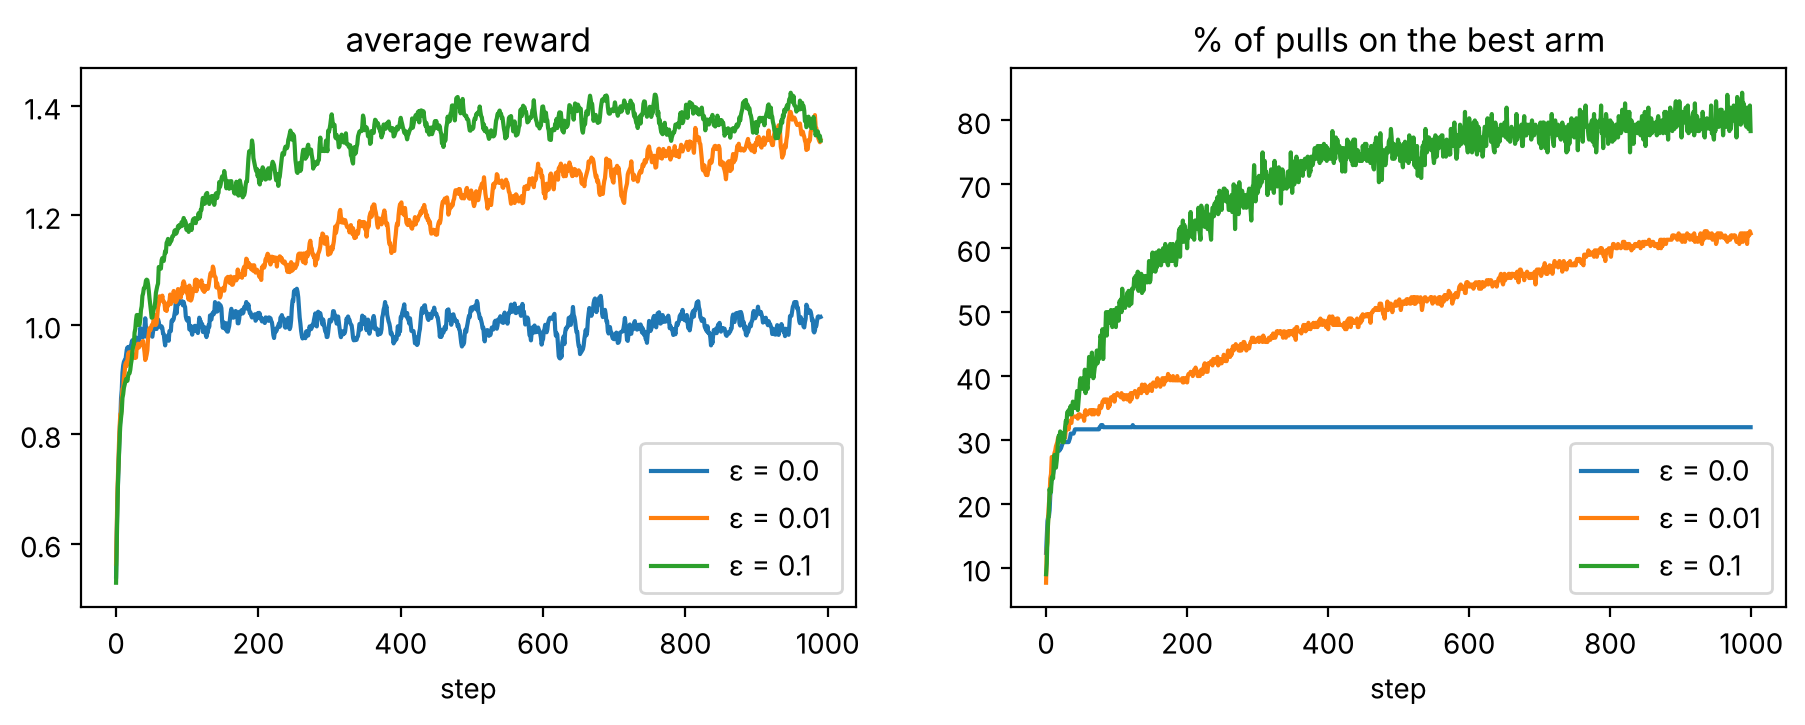

ε = 0.0   average reward (last 100 steps) 1.01   best arm chosen 32%
ε = 0.01  average reward (last 100 steps) 1.35   best arm chosen 62%
ε = 0.1   average reward (last 100 steps) 1.37   best arm chosen 80%


In [21]:
def run_bandit(eps, steps=1000, runs=300, k=10, seed=0):
    rng = np.random.default_rng(seed)
    rewards, optimal = np.zeros(steps), np.zeros(steps)
    for run in range(runs):
        true_means = rng.normal(0, 1, k)
        best = true_means.argmax()
        Q, N = np.zeros(k), np.zeros(k)
        for t in range(steps):
            if rng.random() < eps:
                a = rng.integers(k)  # TODO: explore: a random arm
            else:
                a = int(Q.argmax())  # TODO: exploit: the arm with the highest estimate
            r = rng.normal(true_means[a], 1)
            N[a] += 1
            Q[a] = Q[a] + (r - Q[a]) / N[a]  # TODO: incremental average
            rewards[t] += r; optimal[t] += (a == best)
    return rewards / runs, optimal / runs

bandit = {eps: run_bandit(eps) for eps in [0.0, 0.01, 0.1]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for eps, (rw, opt_) in bandit.items():
    ax[0].plot(smooth(rw, 10), label=f"ε = {eps}"); ax[1].plot(opt_ * 100, label=f"ε = {eps}")
ax[0].set_title("average reward"); ax[1].set_title("% of pulls on the best arm")
for a_ in ax: a_.set_xlabel("step"); a_.legend()
plt.show()
for eps, (rw, opt_) in bandit.items():
    print(f"ε = {eps:<5} average reward (last 100 steps) {rw[-100:].mean():.2f}   best arm chosen {opt_[-100:].mean():.0%}")

In [22]:
best_arm = {e: bandit[e][1][-100:].mean() for e in bandit}
check(best_arm[0.1] > best_arm[0.0] + 0.2,
      "the greedy agent locks onto whichever arm looked good first; a little exploration finds the best arm far more often.",
      "a = rng.integers(k) when exploring, int(Q.argmax()) otherwise; Q[a] += (r - Q[a]) / N[a].")

PASS: the greedy agent locks onto whichever arm looked good first; a little exploration finds the best arm far more often.


**Think about it:** ε = 0.1 wins after 1,000 steps. Which ε would win after 100,000 steps, and why? (Hint: ε = 0.1 keeps wasting 10% of its pulls forever.) How would you combine the best of both?

---
## Exercise 10 (challenge). Reward hacking (slide 16)

A corridor of 8 cells. The agent starts in cell 0 and should reach the **goal** in cell 7 (+10, episode ends).
A designer added a **coin** in cell 2 (+1) "to encourage moving right". But the coin **respawns** every time the agent re-enters the cell…

Like the CoastRunners boat, the agent may find that **circling for coins** pays more than finishing.

**Tasks:** train a tabular Q-learner on the buggy reward, watch its behaviour, then fix the reward so the coin can only be collected **once**.

In [23]:
class Corridor:
    # Actions: 0 = left, 1 = right. Episodes are capped at 50 steps.
    def __init__(self, coin_once=False):
        self.coin_once = coin_once
        self.n_states = 8 * 2                       # position x coin-already-taken flag
    def reset(self):
        self.pos, self.taken, self.t = 0, 0, 0
        return self.state()
    def state(self):
        return self.pos * 2 + self.taken
    def step(self, a):
        self.t += 1
        self.pos = int(np.clip(self.pos + (1 if a == 1 else -1), 0, 7))
        reward, terminated = 0.0, False
        if self.pos == 2 and not (self.coin_once and self.taken):
            reward += 1.0
            if self.coin_once:
                self.taken = 1
        if self.pos == 7:
            reward, terminated = reward + 10.0, True
        return self.state(), reward, terminated, self.t >= 50

def train_corridor(env, episodes=2000, alpha=0.2, gamma=0.99, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, 2))
    for ep in range(episodes):
        eps = max(0.05, 1 - ep / 1000)
        s = env.reset(); done = False
        while not done:
            a = rng.integers(2) if rng.random() < eps else int(Q[s].argmax())
            s2, r, terminated, truncated = env.step(a)
            Q[s, a] += alpha * (r + gamma * Q[s2].max() * (not terminated) - Q[s, a])
            s, done = s2, terminated or truncated
    return Q

def watch(env, Q):
    s = env.reset(); path, total, done = [env.pos], 0.0, False
    while not done:
        s, r, terminated, truncated = env.step(int(Q[s].argmax())); path.append(env.pos); total += r; done = terminated or truncated
    return path, total, env.pos == 7

buggy = Corridor(coin_once=False)
path_b, ret_b, goal_b = watch(buggy, train_corridor(buggy))
print(f"Buggy reward : return {ret_b:.0f}, reached goal: {goal_b}, path: {path_b[:16]} ...")

fixed = Corridor(coin_once=True)
Q_fixed = train_corridor(fixed)
path_f, ret_f, goal_f = watch(fixed, Q_fixed)  # TODO: watch the agent trained on the fixed reward
print(f"Fixed reward : return {ret_f:.0f}, reached goal: {goal_f}, path: {path_f}")

Buggy reward : return 25, reached goal: False, path: [0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1] ...
Fixed reward : return 11, reached goal: True, path: [0, 1, 2, 3, 4, 5, 6, 7]


In [24]:
check((not goal_b) and goal_f,
      "with a respawning coin the agent oscillates around cell 2 forever and never finishes; with the fixed reward it walks straight to the goal.",
      "watch(fixed, Q_fixed) should reach cell 7.")

PASS: with a respawning coin the agent oscillates around cell 2 forever and never finishes; with the fixed reward it walks straight to the goal.


**Think about it:** the buggy agent is not "wrong": it maximises exactly the reward we wrote. How does the same problem appear in **RLHF**, where the reward is a learned reward model? Name two ways to guard against it.

---
## Wrap-up questions (discuss in class)

1. Why does DQN need **both** experience replay and a target network? What goes wrong without each?
2. Q-learning is **off-policy** and REINFORCE is **on-policy**. What does that mean for how each can reuse old data?
3. Write the advantage `A(s, a)` in words. Why is it a better weight for the policy gradient than the raw return?
4. Your DQN agent's score jumps between 500 and 120 from one evaluation to the next. Give two possible reasons and two remedies.
5. For a robot arm with continuous torques, which algorithm from this notebook would you **not** use directly, and what would you use instead?

---
## Answers

**Think-about-it boxes**

* **Ex 2:** 1 / (1 − 0.99) = **100**. Discounting caps the return even for a never-ending episode.
* **Ex 3:** on the slippery lake an intended move succeeds only one time in three; the other two times you slide sideways. Next to a hole, the policy therefore chooses a direction whose *sideways* slips cannot reach the hole, even if that points away from the goal. It is slower but safer.
* **Ex 5 (try it):** with `sync_every=1` the target moves with every update and training becomes much less stable; with a tiny buffer, consecutive, highly correlated samples dominate and the agent tends to forget what it learned.
* **Ex 7:** without a baseline every Gₜ > 0, so **every** action taken becomes more likely, good and bad. Only the *relative* size of the push differs between episodes, so the signal is very noisy and learning is slow. With a baseline, worse-than-average actions are pushed **down**.
* **Ex 9:** after 100,000 steps a smaller ε (e.g. 0.01) wins: it eventually finds the best arm too, and wastes only 1% of its pulls. Combine both by **decaying ε** over time, or use smarter exploration such as optimistic initial values or UCB.
* **Ex 10:** in RLHF the policy can exploit weaknesses of the reward model (e.g. very long or flattering answers that score highly). Guards: a KL penalty that keeps the policy close to the original model, retraining or ensembling reward models, human evaluation of samples, and early stopping.

**Wrap-up**

1. Replay breaks the correlation between consecutive samples and reuses data; without it, updates follow the latest experience and the network forgets. The target network keeps the TD target fixed for a while; without it, the target moves with every update and Q-values can oscillate or diverge.
2. Off-policy (Q-learning, DQN) learns the greedy policy from data generated by any behaviour policy, so it can reuse a replay buffer. On-policy (REINFORCE, PPO) needs data from the current policy, so old data must be discarded or corrected (PPO reuses each batch for only a few epochs, protected by clipping).
3. "How much better taking action a in state s turned out than what the critic expected on average." Subtracting the expected value removes the shared part of the return, which lowers variance and lets bad actions get negative weight.
4. Reasons: the policy is still changing a lot (unstable updates, too high a learning rate, target synced too often) or evaluation over too few episodes. Remedies: evaluate over more episodes and several seeds, lower the learning rate, keep the best checkpoint, use Double DQN or a slower target update.
5. Not DQN (it needs a max over a discrete set of actions). Use SAC, TD3 or PPO with a Gaussian policy.